# 03 — Histograms and Contrast

A histogram summarizes how often intensity values occur, while discarding their spatial arrangement.

## Learning objectives
- Implement an exact 256-bin histogram for uint8 images.
- Measure dynamic range and simulate low contrast.
- Derive min–max and percentile contrast stretching.
- Explain quantization, outlier sensitivity, and irreversible information loss.

Run independently using the bundled `skimage.data.camera()` sample.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
np.set_printoptions(precision=4, suppress=True)

## 1. Histogram and contrast measures

For $N=HW$ pixels and $L=256$ levels,

$$h(k)=\sum_{i,j}\mathbf{1}[I(i,j)=k],\qquad p(k)=h(k)/N,\qquad\sum_k p(k)=1.$$

Dynamic range is $r_{max}-r_{min}$; standard deviation measures global intensity spread. Neither captures spatial structure or guarantees useful perceptual contrast. Two images can share a histogram while showing completely different objects.

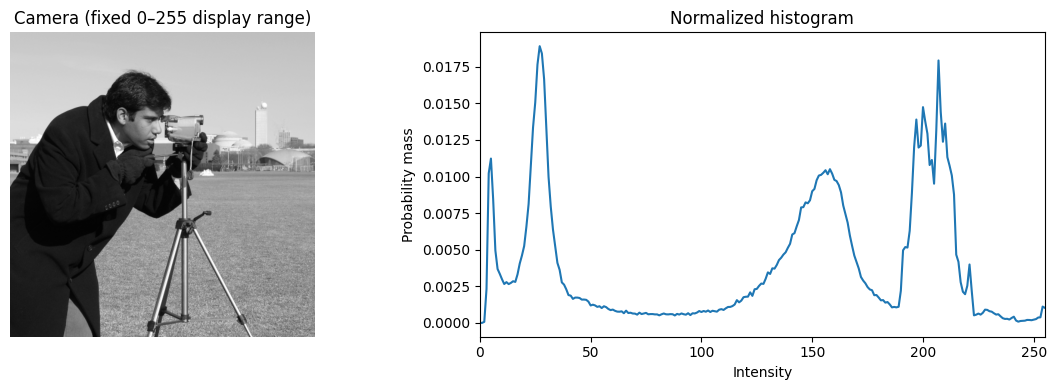

In [2]:
image = data.camera()
assert image.dtype == np.uint8 and image.ndim == 2
histogram = np.zeros(256, dtype=np.int64)
# Accumulate counts from first principles; np.bincount is the fast equivalent.
for value in image.ravel():
    histogram[int(value)] += 1
assert np.array_equal(histogram, np.bincount(image.ravel(), minlength=256))
assert histogram.sum() == image.size
probabilities = histogram / image.size
assert np.isclose(probabilities.sum(), 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(image, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Camera (fixed 0–255 display range)')
axes[0].axis('off')
axes[1].plot(np.arange(256), probabilities)
axes[1].set(xlabel='Intensity', ylabel='Probability mass', title='Normalized histogram', xlim=(0, 255))
plt.tight_layout()
plt.show()

## 2. Simulate and restore low contrast

Compress normalized intensities by $z=a+bx$, with $0<b<1$. Here $a=0.35$, $b=0.25$; uint8 quantization merges distinct input levels. Min–max stretching maps an observed interval $[r_{min},r_{max}]$ to $[0,1]$:

$$s=\frac{r-r_{min}}{r_{max}-r_{min}}.$$

For a constant image the denominator is zero. We explicitly return zeros because no intensity ordering can be recovered. Stretching expands the range but cannot undo quantization or recover lost detail.

Image                  range        std       unique levels
Original             1.0000       0.2888       256
Low contrast         0.2510       0.0722       65
Stretched            1.0000       0.2876       65
Restoration RMSE: 0.005135265400497574


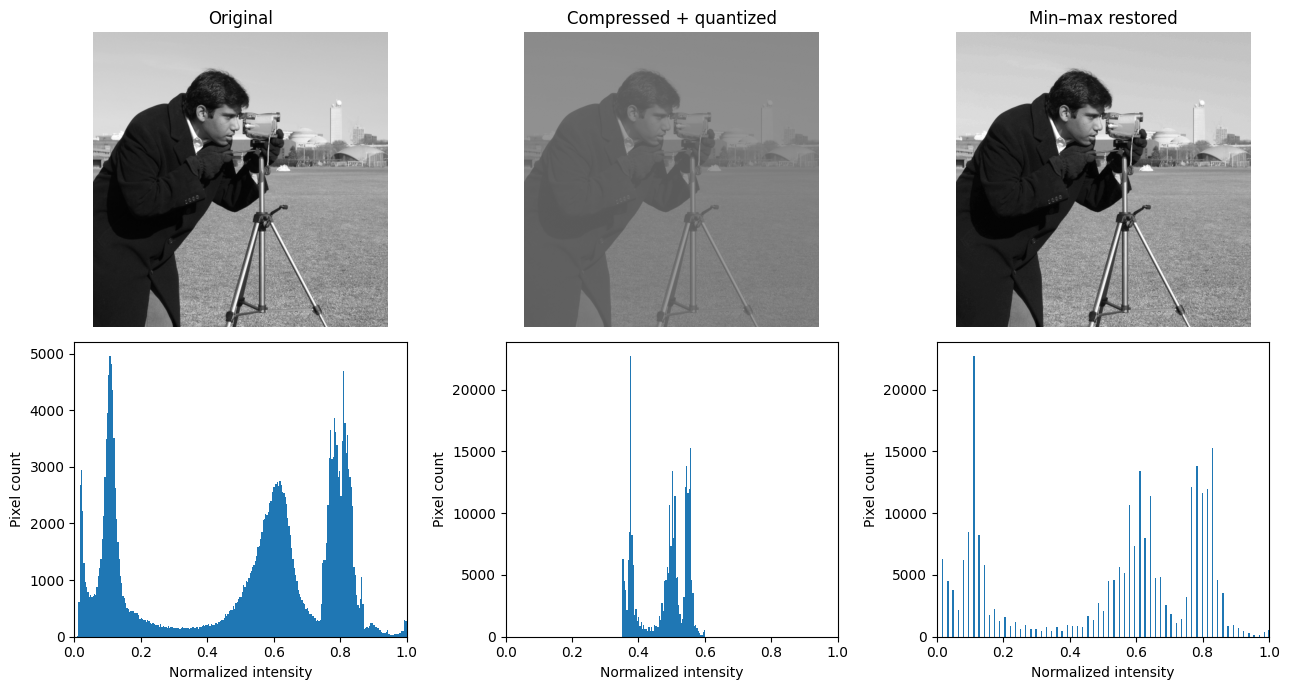

In [3]:
def contrast_stretch(array, low=None, high=None):
    values = np.asarray(array, dtype=np.float64)
    low = float(values.min()) if low is None else float(low)
    high = float(values.max()) if high is None else float(high)
    if high <= low:
        return np.zeros_like(values)
    return np.clip((values - low) / (high - low), 0.0, 1.0)

normalized = image.astype(np.float64) / 255
low_contrast = np.rint(255 * (0.35 + 0.25 * normalized)).astype(np.uint8)
restored = contrast_stretch(low_contrast)
assert np.all(contrast_stretch(np.full((8, 8), 12)) == 0)
assert np.isclose(restored.min(), 0) and np.isclose(restored.max(), 1)
print('Image                  range        std       unique levels')
for name, arr in [('Original', normalized), ('Low contrast', low_contrast / 255), ('Stretched', restored)]:
    print(f'{name:20s} {np.ptp(arr):.4f}       {arr.std():.4f}       {len(np.unique(arr))}')
print('Restoration RMSE:', np.sqrt(np.mean((restored - normalized) ** 2)))

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, (name, arr) in enumerate([('Original', normalized), ('Compressed + quantized', low_contrast / 255), ('Min–max restored', restored)]):
    axes[0, col].imshow(arr, cmap='gray', vmin=0, vmax=1)
    axes[0, col].set_title(name)
    axes[0, col].axis('off')
    axes[1, col].hist(arr.ravel(), bins=256, range=(0, 1))
    axes[1, col].set(xlabel='Normalized intensity', ylabel='Pixel count', xlim=(0, 1))
plt.tight_layout()
plt.show()

## 3. Percentile stretching and outliers

A few extreme pixels can dominate min–max bounds. Use $r_{low}=P_1$ and $r_{high}=P_{99}$ instead, then clip outside that interval. This trades robustness for saturation: pixels below/above the bounds become black/white, losing their mutual differences.

The synthetic extreme pixels below are a controlled experiment, not a realistic noise model. We compare with `skimage.exposure.rescale_intensity` using identical bounds.

Percentile bounds: (np.float64(90.0), np.float64(147.0))
Fraction strictly outside bounds: 0.009552001953125


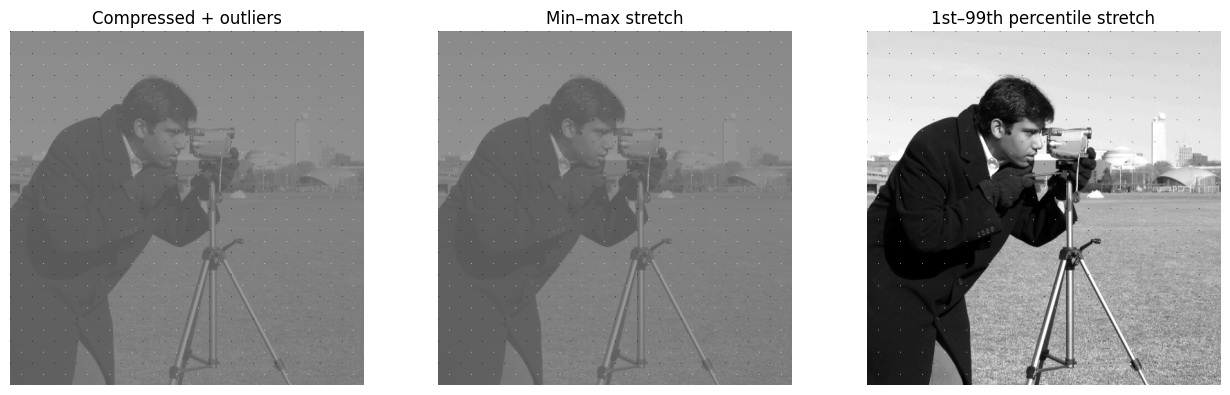

In [4]:
from skimage import exposure

contaminated = low_contrast.copy()
contaminated[::32, ::32] = 0
contaminated[16::32, 16::32] = 255
low, high = np.percentile(contaminated, (1, 99))
robust = contrast_stretch(contaminated, low, high)
minmax = contrast_stretch(contaminated)
library = exposure.rescale_intensity(contaminated.astype(float), in_range=(low, high), out_range=(0, 1))
assert np.allclose(robust, library)
print('Percentile bounds:', (low, high))
print('Fraction strictly outside bounds:', np.mean((contaminated < low) | (contaminated > high)))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, arr, name in zip(axes, [contaminated / 255, minmax, robust],
                         ['Compressed + outliers', 'Min–max stretch', '1st–99th percentile stretch']):
    ax.imshow(arr, cmap='gray', vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Same histogram, different spatial information

Random permutation preserves every intensity count. A histogram cannot distinguish the scene from its shuffled version.

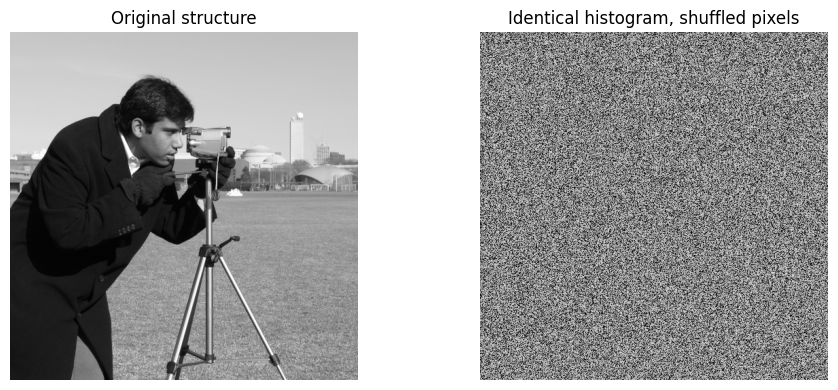

In [5]:
rng = np.random.default_rng(42)
shuffled = rng.permutation(image.ravel()).reshape(image.shape)
assert np.array_equal(np.bincount(shuffled.ravel(), minlength=256), histogram)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, arr, name in zip(axes, [image, shuffled], ['Original structure', 'Identical histogram, shuffled pixels']):
    ax.imshow(arr, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Interpretation, limitations, and review

Compare the unique-level counts before and after stretching: a larger displayed range is not new information. The percentile experiment shows why brightness outliers can make range-based contrast measurements misleading. Low contrast caused by quantization is different from spatially varying illumination or blur.

1. Why can a full-range histogram still correspond to a poor image?
2. How does increasing the percentile cutoff change saturation and local detail?
3. Can the original image be recovered exactly after compression to uint8? Explain.
4. Which experiment proves that a histogram does not describe object structure?

## Summary and connection

Contrast stretching is a pointwise affine mapping followed by optional clipping. It is useful preprocessing in Computer Vision, but histogram statistics must be combined with spatial reasoning. Deep Learning normalization also rescales inputs; changing image contrast independently can affect the distribution expected by a trained model.